# Évaluation des métriques pour les tâches de vision par ordinateur

**Notebook pédagogique — données réelles, annotations réelles et prédictions de modèles.**

Ce notebook présente et calcule les métriques d'évaluation pour quatre familles de tâches :

1. **Classification d'images** — CIFAR-10, avec un réseau de neurones convolutif (CNN) ResNet-18 adapté aux images 32 × 32 ;
2. **Détection d'objets** — Penn-Fudan Pedestrian ;
3. **Segmentation sémantique** — Penn-Fudan Pedestrian ;
4. **Segmentation par instance** — Penn-Fudan Pedestrian.

Les données sont réelles. Pour la classification, le modèle est entraîné sur la partie entraînement officielle de CIFAR-10, avec un jeu de validation prélevé uniquement dans cette partie. Le jeu de test officiel reste réservé à l'évaluation finale. Pour la détection et les segmentations, le notebook utilise **Mask R-CNN pré-entraîné sur COCO** et l'évalue sur les annotations réelles de Penn-Fudan.

> **Important :** l'entraînement du CNN peut prendre plusieurs minutes. Un GPU est fortement recommandé (par exemple Google Colab avec accélérateur GPU). Le notebook inclut une validation, une régularisation, une augmentation de données et un arrêt anticipé pour limiter le surapprentissage (*overfitting*).

## Objectifs pédagogiques

- construire et interpréter une matrice de confusion ;
- calculer précision, rappel, F1-score, accuracy, ROC-AUC et Top-k accuracy ;
- calculer l'IoU pour les boîtes et les masques ;
- comprendre l'AP et la mAP à plusieurs seuils d'IoU ;
- distinguer segmentation sémantique et segmentation par instance ;
- séparer correctement entraînement, validation et test ;
- détecter un modèle qui prédit presque toujours la même classe.

---

## 1. Jeux de données et provenance

| Tâche | Jeu de données | Annotations utilisées |
|---|---|---|
| Classification | [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) | Une classe parmi 10 par image ; 50 000 images d'entraînement et 10 000 images de test |
| Détection | [Penn-Fudan Pedestrian](https://www.cis.upenn.edu/~jshi/ped_html/) | Une instance de piéton par masque ; les boîtes sont calculées depuis les masques |
| Segmentation sémantique | Penn-Fudan Pedestrian | Fusion des masques d'instances en un masque binaire « piéton / arrière-plan » |
| Segmentation par instance | Penn-Fudan Pedestrian | Un masque distinct pour chaque piéton |

Le tutoriel officiel de TorchVision décrit Penn-Fudan comme un jeu de **170 images et 345 instances de piétons** : [tutoriel TorchVision](https://docs.pytorch.org/tutorials/intermediate/torchvision_tutorial.html).

### Références

- CIFAR-10 : Krizhevsky, *Learning Multiple Layers of Features from Tiny Images* ; [site officiel](https://www.cs.toronto.edu/~kriz/cifar.html).
- Penn-Fudan : [page du jeu de données](https://www.cis.upenn.edu/~jshi/ped_html/).
- Classification : [documentation officielle ResNet-18 de TorchVision](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html).
- Détection/segmentation : [Mask R-CNN ResNet-50 FPN](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.detection.maskrcnn_resnet50_fpn.html).

## 2. Installation, imports et configuration

Le notebook est conçu pour JupyterLab, Jupyter Notebook et Google Colab. PyTorch et TorchVision sont nécessaires pour la partie détection/segmentation. Dans Colab, ils sont généralement préinstallés. Pour une installation locale, choisissez une version de TorchVision compatible avec votre version de PyTorch : [guide officiel d'installation](https://pytorch.org/get-started/locally/).

Les bibliothèques de métriques et de visualisation peuvent être installées avec la cellule suivante.

In [ ]:
# Décommentez cette ligne si scikit-learn ou les bibliothèques de visualisation manquent.
# %pip install -q scikit-learn matplotlib pandas pillow tqdm

import os
import random
import urllib.request
import zipfile
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
try:
    from tqdm.auto import tqdm  # barre de progression pendant les longues boucles
except ImportError:
    print("Installez tqdm avec : %pip install tqdm")
    def tqdm(iterable, **kwargs):
        return iterable  # fonctionnement sans barre si tqdm est absent
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import CIFAR10
from torchvision import transforms
from torchvision.models import resnet18
from torchvision.models.detection import (
    maskrcnn_resnet50_fpn,
    MaskRCNN_ResNet50_FPN_Weights,
)
from torchvision.transforms import functional as TF

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

from PIL import Image

# Fixer les graines facilite la reproductibilité des séparations et de l'initialisation.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Choix automatique du matériel disponible.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("data_vision")
DATA_DIR.mkdir(parents=True, exist_ok=True)

print(f"PyTorch      : {torch.__version__}")
print(f"TorchVision  : {torchvision.__version__}")
print(f"Matériel     : {DEVICE}")
print(f"Dossier data : {DATA_DIR.resolve()}")

# Le modèle de détection utilisé plus loin demande TorchVision >= 0.16.
from packaging.version import Version
assert Version(torchvision.__version__.split('+')[0]) >= Version("0.16"), (
    "Mettez TorchVision à niveau vers une version >= 0.16. "
    "Consultez https://pytorch.org/get-started/locally/"
)

PyTorch      : 2.14.1+cu130
TorchVision  : 0.29.1+cu130
Matériel     : cuda
Dossier data : /content/data_vision


## 3. Classification d'images avec CIFAR-10

### 3.1 Présentation du problème et diagnostic du modèle précédent

CIFAR-10 contient 60 000 images couleur de 32 × 32 pixels réparties en 10 classes : avion, automobile, oiseau, chat, cerf, chien, grenouille, cheval, bateau et camion. La séparation officielle comprend 50 000 images d'entraînement et 10 000 images de test.

Le premier modèle utilisait `SGDClassifier` sur les pixels aplatis. Il ne disposait d'aucune architecture pour exploiter la structure spatiale des images. La matrice de confusion fournie montre un **effondrement des prédictions** : 1 903 images sur 3 000 étaient classées « chat » (63,4 %). Ce comportement ne signifie pas que le jeu de données contient trop de chats : CIFAR-10 est équilibré.

Nous le remplaçons par un **ResNet-18 adapté à CIFAR-10**. Son premier bloc conserve mieux la résolution 32 × 32 (convolution 3 × 3, stride 1, sans max-pooling initial). Le modèle apprend des caractéristiques spatiales plutôt que de traiter chaque pixel comme une variable indépendante.

### Stratégie anti-surapprentissage

- séparation stratifiée **entraînement / validation** à partir des 50 000 images d'entraînement officielles ;
- transformations aléatoires uniquement pendant l'entraînement : recadrage avec padding et retournement horizontal ;
- normalisation avec les statistiques usuelles de CIFAR-10 ;
- pénalisation L2 (`weight_decay`) et léger *label smoothing* ;
- décroissance du taux d'apprentissage ;
- arrêt anticipé (*early stopping*) selon la perte de validation ;
- évaluation finale une seule fois sur le jeu de test officiel.

**Important :** n'ajustez pas les hyperparamètres en regardant les résultats du jeu de test. Utilisez la validation pour choisir le nombre d'époques et les réglages.

In [ ]:
# Télécharger les deux partitions officielles de CIFAR-10.
cifar_train_raw = CIFAR10(root=DATA_DIR / "cifar10", train=True, download=True)
cifar_test_raw = CIFAR10(root=DATA_DIR / "cifar10", train=False, download=True)

# On utilise toutes les images officielles d'entraînement et toutes les images de test.
X_train_all = cifar_train_raw.data
Y_train_all = np.asarray(cifar_train_raw.targets)
X_test_all = cifar_test_raw.data
Y_test_all = np.asarray(cifar_test_raw.targets)
CLASS_NAMES = cifar_train_raw.classes

# 10 % de la partition d'entraînement est réservée à la validation.
# La partition de test officielle n'est jamais utilisée pendant l'entraînement.
indices_train, indices_val = train_test_split(
    np.arange(len(Y_train_all)),
    test_size=0.10,
    stratify=Y_train_all,
    random_state=SEED,
)

print("Classes :", CLASS_NAMES)
print(f"Entraînement : {len(indices_train):,} images")
print(f"Validation  : {len(indices_val):,} images")
print(f"Test officiel : {len(Y_test_all):,} images")

# Vérifier que les 10 classes sont présentes dans chaque partition.
print("Effectifs entraînement :", np.bincount(Y_train_all[indices_train], minlength=10))
print("Effectifs validation   :", np.bincount(Y_train_all[indices_val], minlength=10))
print("Effectifs test         :", np.bincount(Y_test_all, minlength=10))

100%|██████████| 170M/170M [02:22<00:00, 1.19MB/s]


Classes : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Entraînement : 45,000 images
Validation  : 5,000 images
Test officiel : 10,000 images
Effectifs entraînement : [4500 4500 4500 4500 4500 4500 4500 4500 4500 4500]
Effectifs validation   : [500 500 500 500 500 500 500 500 500 500]
Effectifs test         : [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


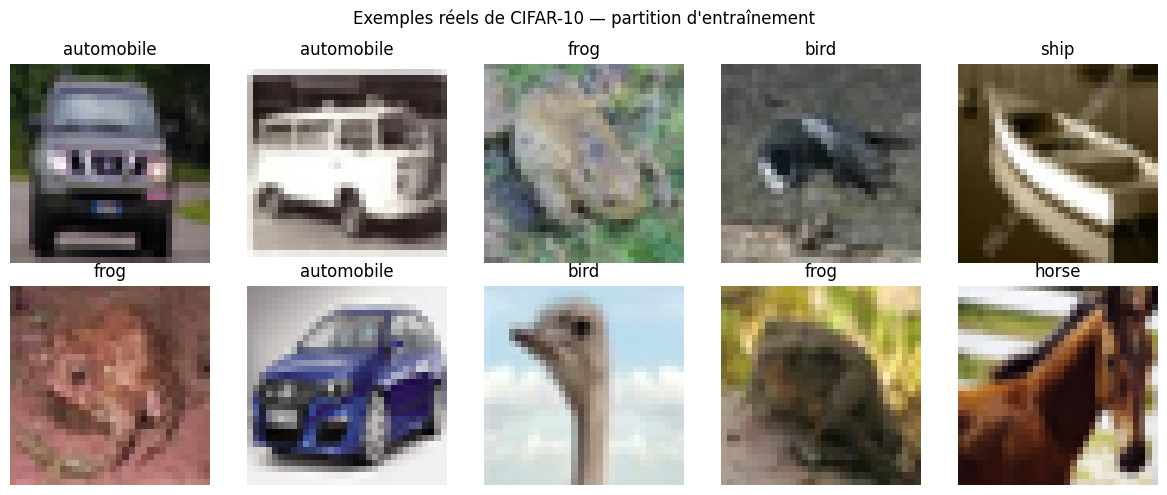

In [ ]:
# Visualiser quelques images réelles de CIFAR-10.
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.flat, indices_train[:10]):
    ax.imshow(X_train_all[idx])
    ax.set_title(CLASS_NAMES[Y_train_all[idx]])
    ax.axis("off")
plt.suptitle("Exemples réels de CIFAR-10 — partition d'entraînement")
plt.tight_layout()
plt.show()

### 3.2 Préparation des données et du modèle CNN

Les transformations de validation et de test sont déterministes : elles ne modifient pas artificiellement les images. L'augmentation de données est appliquée uniquement aux images d'entraînement.

Les dix classes de CIFAR-10 sont équilibrées. **Nous n'utilisons donc pas de poids de classes ni de sur-échantillonnage**, qui ne sont pas nécessaires ici.

In [ ]:
# Statistiques RGB couramment utilisées pour normaliser CIFAR-10.
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

# Augmentations légères : elles créent de la variété sans changer la classe.
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

# Aucune augmentation aléatoire en validation ou en test.
transform_eval = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

# Deux vues du même jeu d'entraînement : même contenu, transformations différentes.
dataset_train_complet = CIFAR10(
    root=DATA_DIR / "cifar10", train=True, download=False, transform=transform_train
)
dataset_val_complet = CIFAR10(
    root=DATA_DIR / "cifar10", train=True, download=False, transform=transform_eval
)
dataset_test = CIFAR10(
    root=DATA_DIR / "cifar10", train=False, download=False, transform=transform_eval
)

train_dataset = Subset(dataset_train_complet, indices_train.tolist())
val_dataset = Subset(dataset_val_complet, indices_val.tolist())

# Sur CPU, num_workers=0 est plus compatible avec les systèmes Windows/Jupyter.
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0
BATCH_SIZE = 128
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
test_loader = DataLoader(
    dataset_test, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)


def construire_resnet18_cifar10():
    """Construit ResNet-18 sans poids ImageNet, adapté aux images 32 x 32."""
    modele = resnet18(weights=None)

    # Le stem ImageNet (7x7 + stride 2 + max-pooling) réduit trop tôt les petites images.
    modele.conv1 = nn.Conv2d(
        3, 64, kernel_size=3, stride=1, padding=1, bias=False
    )
    modele.maxpool = nn.Identity()

    # Dropout léger avant le classifieur pour réduire la co-adaptation des neurones.
    nombre_entrees = modele.fc.in_features
    modele.fc = nn.Sequential(
        nn.Dropout(p=0.25),
        nn.Linear(nombre_entrees, 10)
    )
    return modele

modele_classification = construire_resnet18_cifar10().to(DEVICE)

# Vérification rapide de la forme des entrées et des sorties du réseau.
lot_images, lot_labels = next(iter(train_loader))
with torch.no_grad():
    lot_logits = modele_classification(lot_images[:4].to(DEVICE))
assert lot_logits.shape == (4, 10), f"Sortie inattendue : {lot_logits.shape}"
print("Dimensions des images :", tuple(lot_images.shape))
print("Dimensions des logits :", tuple(lot_logits.shape))
print("Le modèle produit bien 10 scores, un par classe.")

Dimensions des images : (128, 3, 32, 32)
Dimensions des logits : (4, 10)
Le modèle produit bien 10 scores, un par classe.


In [ ]:
# Diagnostic avant l'entraînement : vérifier le GPU et la taille du travail.
# Si DEVICE affiche "cpu", le réseau ResNet-18 peut être lent : activez un GPU dans Colab.
print("Périphérique utilisé :", DEVICE, flush=True)
if DEVICE.type == "cuda":
    print("GPU détecté :", torch.cuda.get_device_name(0), flush=True)
else:
    print("ATTENTION : aucun GPU CUDA détecté. L'entraînement ResNet-18 sera beaucoup plus lent.", flush=True)

print(f"Images d'entraînement : {len(train_dataset):,}", flush=True)
print(f"Images de validation : {len(val_dataset):,}", flush=True)
print(f"Lots par époque : {len(train_loader)} entraînement + {len(val_loader)} validation", flush=True)
print(f"Taille des lots : {BATCH_SIZE} | Workers : {NUM_WORKERS}", flush=True)


Périphérique utilisé : cuda
GPU détecté : Tesla T4
Images d'entraînement : 45,000
Images de validation : 5,000
Lots par époque : 352 entraînement + 40 validation
Taille des lots : 128 | Workers : 2


In [ ]:
# Entraînement avec barre de progression, régularisation et arrêt anticipé.
# IMPORTANT : le diagnostic juste au-dessus doit afficher cuda pour utiliser le GPU.
# Dans Google Colab : Exécution > Modifier le type d'exécution > GPU, puis relancer
# les cellules depuis le début (il ne suffit pas de relancer uniquement cette cellule).

NB_EPOCHS_MAX = 30
PATIENCE = 7
LEARNING_RATE = 0.1
WEIGHT_DECAY = 5e-4
LABEL_SMOOTHING = 0.05

# La précision mixte accélère souvent ResNet sur GPU et réduit l'utilisation mémoire.
# Elle est automatiquement désactivée sur CPU.
UTILISER_AMP = (DEVICE.type == "cuda")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True

critere_train = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
# Pour mesurer la validation, on utilise une cross-entropie standard (sans lissage).
critere_val = nn.CrossEntropyLoss()

optimiseur = torch.optim.SGD(
    modele_classification.parameters(),
    lr=LEARNING_RATE,
    momentum=0.9,
    weight_decay=WEIGHT_DECAY,
    nesterov=True,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimiseur, T_max=NB_EPOCHS_MAX, eta_min=1e-4
)

# GradScaler n'est activé que sur GPU CUDA.
scaler = torch.cuda.amp.GradScaler(enabled=UTILISER_AMP)

historique = {
    "loss_train": [], "loss_val": [],
    "accuracy_train": [], "accuracy_val": [],
}
meilleure_loss_val = float("inf")
meilleur_etat = copy.deepcopy(modele_classification.state_dict())
epoques_sans_progres = 0
meilleure_epoque = 0

print("Début de l'entraînement…", flush=True)
print(f"Mode : {'GPU + précision mixte' if UTILISER_AMP else 'CPU / précision standard'}", flush=True)
print(f"Une époque comporte {len(train_loader)} lots d'entraînement et {len(val_loader)} lots de validation.", flush=True)

for epoque in range(1, NB_EPOCHS_MAX + 1):
    # -------------------- Phase d'entraînement --------------------
    modele_classification.train()
    somme_loss_train = 0.0
    bonnes_predictions_train = 0
    total_train = 0

    barre_train = tqdm(
        train_loader,
        desc=f"Époque {epoque:02d}/{NB_EPOCHS_MAX} — entraînement",
        unit="lot",
        dynamic_ncols=True,
        leave=False,
    )
    for numero_lot, (images, labels) in enumerate(barre_train, start=1):
        images = images.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
        labels = labels.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))

        optimiseur.zero_grad(set_to_none=True)
        # autocast utilise float16 uniquement sur CUDA ; sur CPU, calcul standard.
        with torch.cuda.amp.autocast(enabled=UTILISER_AMP):
            logits = modele_classification(images)
            loss = critere_train(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimiseur)
        scaler.update()

        taille_lot = labels.size(0)
        somme_loss_train += loss.detach().item() * taille_lot
        bonnes_predictions_train += (logits.detach().argmax(dim=1) == labels).sum().item()
        total_train += taille_lot

        # Affiche régulièrement les indicateurs du lot courant.
        acc_courante = bonnes_predictions_train / total_train
        barre_train.set_postfix(
            loss=f"{somme_loss_train / total_train:.3f}",
            acc=f"{acc_courante:.1%}",
        )

    loss_train = somme_loss_train / total_train
    acc_train = bonnes_predictions_train / total_train

    # -------------------- Phase de validation --------------------
    modele_classification.eval()
    somme_loss_val = 0.0
    bonnes_predictions_val = 0
    total_val = 0

    barre_val = tqdm(
        val_loader,
        desc=f"Époque {epoque:02d}/{NB_EPOCHS_MAX} — validation",
        unit="lot",
        dynamic_ncols=True,
        leave=False,
    )
    with torch.inference_mode():
        for images, labels in barre_val:
            images = images.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
            labels = labels.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
            with torch.cuda.amp.autocast(enabled=UTILISER_AMP):
                logits = modele_classification(images)
                loss = critere_val(logits, labels)

            taille_lot = labels.size(0)
            somme_loss_val += loss.item() * taille_lot
            bonnes_predictions_val += (logits.argmax(dim=1) == labels).sum().item()
            total_val += taille_lot
            barre_val.set_postfix(loss=f"{somme_loss_val / total_val:.3f}")

    loss_val = somme_loss_val / total_val
    acc_val = bonnes_predictions_val / total_val

    historique["loss_train"].append(loss_train)
    historique["loss_val"].append(loss_val)
    historique["accuracy_train"].append(acc_train)
    historique["accuracy_val"].append(acc_val)
    scheduler.step()

    # Sauvegarder uniquement le meilleur modèle selon la perte de validation.
    if loss_val < meilleure_loss_val:
        meilleure_loss_val = loss_val
        meilleur_etat = copy.deepcopy(modele_classification.state_dict())
        meilleure_epoque = epoque
        epoques_sans_progres = 0
    else:
        epoques_sans_progres += 1

    print(
        f"Époque {epoque:02d}/{NB_EPOCHS_MAX} | "
        f"loss train={loss_train:.4f} | acc train={acc_train:.3f} | "
        f"loss val={loss_val:.4f} | acc val={acc_val:.3f} | "
        f"meilleure époque={meilleure_epoque}",
        flush=True,
    )

    if epoques_sans_progres >= PATIENCE:
        print(f"Arrêt anticipé : aucune amélioration de la validation depuis {PATIENCE} époques.", flush=True)
        break

# Recharger les poids de la meilleure époque de validation.
modele_classification.load_state_dict(meilleur_etat)
modele_classification.eval()

CHEMIN_MODELE = DATA_DIR / "resnet18_cifar10_meilleur.pth"
torch.save({
    "state_dict": meilleur_etat,
    "classes": CLASS_NAMES,
    "normalisation_mean": CIFAR_MEAN,
    "normalisation_std": CIFAR_STD,
}, CHEMIN_MODELE)

print(f"Meilleure époque : {meilleure_epoque}")
print(f"Modèle sauvegardé : {CHEMIN_MODELE}")
print(f"Meilleure loss de validation : {meilleure_loss_val:.4f}")


Début de l'entraînement…
Mode : GPU + précision mixte
Une époque comporte 352 lots d'entraînement et 40 lots de validation.


/tmp/ipykernel_520/3012435927.py:34: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=UTILISER_AMP)


Époque 01/30 — entraînement:   0%|          | 0/352 [00:00<?, ?lot/s]

/tmp/ipykernel_520/3012435927.py:69: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=UTILISER_AMP):


Époque 01/30 — validation:   0%|          | 0/40 [00:00<?, ?lot/s]

/tmp/ipykernel_520/3012435927.py:109: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=UTILISER_AMP):


... (103 outputs left out)

Époque 30/30 — entraînement:   0%|          | 0/352 [00:00<?, ?lot/s]

Époque 30/30 — validation:   0%|          | 0/40 [00:00<?, ?lot/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79af0475dda0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Exception ignored in:     self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    <function _MultiProcessingDataLoaderIter.__del__ at 0x79af0475dda0>if w.is_alive():

Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    assert self._parent_pid == os.getpid(), 'can only test a child process'    
self._shutdown_workers()AssertionError
:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
can only test a child process    
if w.is_alive():
  File "/usr/lib/

Époque 30/30 | loss train=0.3090 | acc train=0.994 | loss val=0.2435 | acc val=0.936 | meilleure époque=30
Meilleure époque : 30
Modèle sauvegardé : data_vision/resnet18_cifar10_meilleur.pth
Meilleure loss de validation : 0.2435


### 3.3 Accuracy, précision, rappel et F1-score

Après entraînement, nous prédisons les classes des **10 000 images du jeu de test officiel**. Les probabilités `y_proba` et les étiquettes `y_pred` proviennent du CNN ResNet-18 ayant obtenu la meilleure perte de validation.

Pour une classification binaire, les quantités de base sont :

- **VP (TP)** : positifs correctement prédits ;
- **VN (TN)** : négatifs correctement prédits ;
- **FP** : négatifs prédits positifs ;
- **FN** : positifs réels manqués.

En classification multiclasse, ces métriques sont calculées par classe puis agrégées. La moyenne **macro** donne le même poids à chaque classe ; la moyenne **pondérée** tient compte du nombre d'exemples par classe.

> Le jeu de test n'est utilisé qu'ici, après le choix des meilleurs poids sur la validation.

In [ ]:
# Inférence finale sur le jeu de test officiel (jamais vu pendant l'entraînement).
modele_classification.eval()
listes_logits = []
listes_labels = []

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        logits = modele_classification(images)
        probabilites = torch.softmax(logits, dim=1)
        listes_logits.append(probabilites.cpu().numpy())
        listes_labels.append(labels.numpy())

y_proba = np.concatenate(listes_logits, axis=0)
y_test = np.concatenate(listes_labels, axis=0)
y_pred = y_proba.argmax(axis=1)

assert y_proba.shape == (len(dataset_test), 10)
assert len(y_pred) == len(y_test)

# Rapporter les métriques globales et macro/pondérées.
resultats_classification = pd.DataFrame({
    "Métrique": [
        "Accuracy", "Balanced accuracy",
        "Précision macro", "Rappel macro", "F1 macro",
        "Précision pondérée", "Rappel pondéré", "F1 pondéré",
    ],
    "Valeur": [
        accuracy_score(y_test, y_pred),
        balanced_accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average="macro", zero_division=0),
        recall_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test, y_pred, average="macro", zero_division=0),
        precision_score(y_test, y_pred, average="weighted", zero_division=0),
        recall_score(y_test, y_pred, average="weighted", zero_division=0),
        f1_score(y_test, y_pred, average="weighted", zero_division=0),
    ],
})
display(resultats_classification.style.format({"Valeur": "{:.4f}"}))

print("Rapport détaillé par classe :")
print(classification_report(
    y_test, y_pred,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0,
))

,Métrique,Valeur
0,Accuracy,0.9315
1,Balanced accuracy,0.9315
2,Précision macro,0.9316
3,Rappel macro,0.9315
4,F1 macro,0.9315
5,Précision pondérée,0.9316
6,Rappel pondéré,0.9315
7,F1 pondéré,0.9315


Rapport détaillé par classe :
              precision    recall  f1-score   support

    airplane       0.93      0.94      0.94      1000
  automobile       0.96      0.97      0.96      1000
        bird       0.92      0.91      0.91      1000
         cat       0.85      0.86      0.85      1000
        deer       0.93      0.94      0.93      1000
         dog       0.90      0.89      0.89      1000
        frog       0.94      0.95      0.95      1000
       horse       0.97      0.95      0.96      1000
        ship       0.96      0.96      0.96      1000
       truck       0.96      0.95      0.96      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
airplane,941,4,14,9,5,0,1,1,19,6
automobile,6,972,0,0,0,0,1,0,4,17
bird,14,1,906,20,17,15,19,5,2,1
cat,5,2,20,857,13,67,19,9,6,2
deer,4,1,12,19,939,7,9,8,1,0
dog,2,1,13,67,12,888,6,11,0,0
frog,5,0,13,18,9,3,950,0,1,1
horse,8,0,3,8,18,12,0,950,1,0
ship,18,5,2,5,2,0,1,0,959,8
truck,5,29,1,3,0,0,0,0,9,953


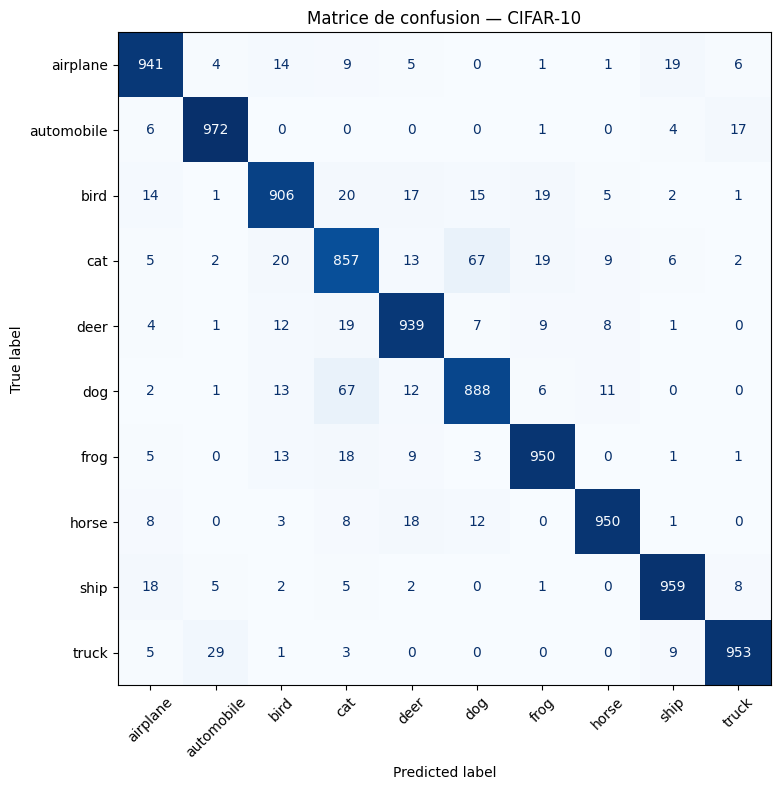

In [ ]:
# Matrice de confusion : lignes = vraies classes, colonnes = classes prédites.
cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(CLASS_NAMES)))
display(pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False
)
ax.set_title("Matrice de confusion — CIFAR-10")
plt.tight_layout()
plt.show()


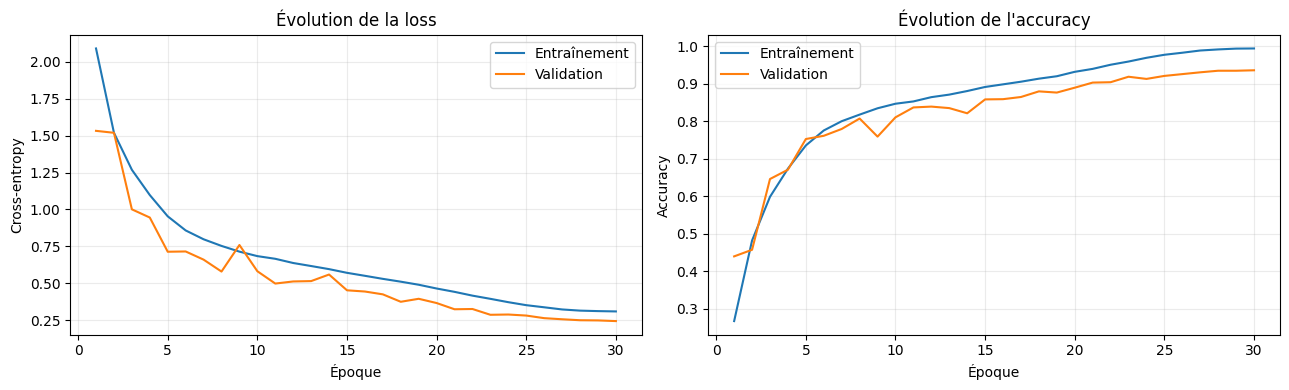

,Classe,Nombre prédit,Part (%)
0,airplane,1008,10.08
1,automobile,1015,10.15
2,bird,984,9.84
3,cat,1006,10.06
4,deer,1015,10.15
5,dog,992,9.92
6,frog,1006,10.06
7,horse,984,9.84
8,ship,1002,10.02
9,truck,988,9.88


Nombre de classes prédites : 10 / 10


In [ ]:
# Courbes d'apprentissage : un écart train/validation croissant peut signaler l'overfitting.
epoques = np.arange(1, len(historique["loss_train"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epoques, historique["loss_train"], label="Entraînement")
axes[0].plot(epoques, historique["loss_val"], label="Validation")
axes[0].set_title("Évolution de la loss")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Cross-entropy")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(epoques, historique["accuracy_train"], label="Entraînement")
axes[1].plot(epoques, historique["accuracy_val"], label="Validation")
axes[1].set_title("Évolution de l'accuracy")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Distribution des classes prédites : un modèle sain ne devrait pas tout attribuer à une classe.
effectifs_predits = np.bincount(y_pred, minlength=len(CLASS_NAMES))
distribution_predite = pd.DataFrame({
    "Classe": CLASS_NAMES,
    "Nombre prédit": effectifs_predits,
    "Part (%)": 100 * effectifs_predits / len(y_pred),
})
display(distribution_predite)
print("Nombre de classes prédites :", int((effectifs_predits > 0).sum()), "/", len(CLASS_NAMES))

### 3.4 Top-k accuracy et ROC-AUC

- **Top-1 accuracy** correspond à l'accuracy habituelle.
- **Top-5 accuracy** est correcte si la vraie classe figure parmi les cinq classes ayant les plus grandes probabilités.
- **ROC-AUC multiclasse** est calculée en mode *one-vs-rest* et moyennée sur les classes.

L'AUC exige des scores ou probabilités, pas uniquement les étiquettes prédites.

In [ ]:
def top_k_accuracy(y_true, proba, k=5):
    """Part des exemples dont la vraie classe figure dans les k scores les plus élevés."""
    indices_top_k = np.argsort(proba, axis=1)[:, -k:]
    return np.mean([vrai in candidats for vrai, candidats in zip(y_true, indices_top_k)])

print(f"Top-1 accuracy : {top_k_accuracy(y_test, y_proba, k=1):.4f}")
print(f"Top-5 accuracy : {top_k_accuracy(y_test, y_proba, k=5):.4f}")

# ROC-AUC macro one-vs-rest ; utile pour comparer le classement des classes.
auc_macro_ovr = roc_auc_score(
    y_test, y_proba, multi_class="ovr", average="macro"
)
print(f"ROC-AUC macro (OvR) : {auc_macro_ovr:.4f}")


Top-1 accuracy : 0.9315
Top-5 accuracy : 0.9973
ROC-AUC macro (OvR) : 0.9946


### 3.5 Quand utiliser ces métriques ?

| Métrique | Quand elle est utile | Point de vigilance |
|---|---|---|
| Accuracy | Classes équilibrées et coût des erreurs similaire | Peut masquer une classe rare mal reconnue |
| Précision | Les faux positifs sont coûteux | Ne mesure pas les positifs manqués |
| Rappel | Les faux négatifs sont coûteux | Peut augmenter au prix de nombreux faux positifs |
| F1-score | Compromis précision/rappel | Ne prend pas en compte les vrais négatifs |
| Balanced accuracy | Classes déséquilibrées | Moyenne le rappel des classes |
| Top-k accuracy | Plusieurs réponses plausibles ou interface de recommandation | Ne dit pas si la première prédiction est correcte |
| ROC-AUC | Comparaison de scores sur plusieurs seuils | Peut être optimiste en présence de très fortes classes rares ; compléter par PR-AUC |

---

## 4. Détection d'objets avec Penn-Fudan Pedestrian

### 4.1 Télécharger et inspecter les annotations réelles

Penn-Fudan fournit des images de rue avec des masques où chaque valeur non nulle identifie une instance de piéton. Nous dérivons les boîtes englobantes directement des pixels de chaque masque. Les coordonnées sont au format `[x_min, y_min, x_max, y_max]`.

In [ ]:
PENN_FUDAN_URL = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
PENN_ZIP = DATA_DIR / "PennFudanPed.zip"

# Télécharger l'archive uniquement si elle n'est pas déjà présente.
if not PENN_ZIP.exists():
    print("Téléchargement de Penn-Fudan Pedestrian...")
    urllib.request.urlretrieve(PENN_FUDAN_URL, PENN_ZIP)
else:
    print("Archive Penn-Fudan déjà présente.")

# Extraire uniquement si les dossiers d'images ne sont pas encore présents.
if not list(DATA_DIR.rglob("PNGImages")):
    with zipfile.ZipFile(PENN_ZIP, "r") as archive:
        archive.extractall(DATA_DIR)

image_dirs = list(DATA_DIR.rglob("PNGImages"))
assert image_dirs, "Dossier PNGImages introuvable après extraction."
PENN_ROOT = image_dirs[0].parent
IMAGE_DIR = PENN_ROOT / "PNGImages"
MASK_DIR = PENN_ROOT / "PedMasks"

print("Racine Penn-Fudan :", PENN_ROOT)
print("Nombre d'images   :", len(list(IMAGE_DIR.glob("*.png"))))
print("Nombre de masques :", len(list(MASK_DIR.glob("*_mask.png"))))


Téléchargement de Penn-Fudan Pedestrian...
Racine Penn-Fudan : data_vision/PennFudanPed
Nombre d'images   : 170
Nombre de masques : 170


In [ ]:
class PennFudanDataset(torch.utils.data.Dataset):
    """Lit les images et les masques d'instances natifs de Penn-Fudan."""
    def __init__(self, image_dir, mask_dir):
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.image_paths = sorted(self.image_dir.glob("*.png"))
        if not self.image_paths:
            raise RuntimeError(f"Aucune image trouvée dans {self.image_dir}")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]
        mask_path = self.mask_dir / f"{image_path.stem}_mask.png"

        # L'image RGB et le masque indexé sont lus depuis les fichiers originaux.
        image = np.asarray(Image.open(image_path).convert("RGB"))
        mask_indexe = np.asarray(Image.open(mask_path))

        # Chaque valeur non nulle représente une instance distincte.
        ids_instances = np.unique(mask_indexe)
        ids_instances = ids_instances[ids_instances != 0]

        masques = []
        boites = []
        for instance_id in ids_instances:
            masque = (mask_indexe == instance_id)
            ys, xs = np.where(masque)
            if len(xs) == 0:
                continue
            # +1 sur x_max/y_max pour respecter la convention de boîtes XYXY.
            boites.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])
            masques.append(masque)

        hauteur, largeur = mask_indexe.shape
        if masques:
            masques = np.stack(masques, axis=0).astype(bool)
            boites = np.asarray(boites, dtype=np.float32)
        else:
            masques = np.zeros((0, hauteur, largeur), dtype=bool)
            boites = np.zeros((0, 4), dtype=np.float32)

        return {
            "image": image,
            "masks": masques,
            "boxes": boites,
            "labels": np.ones(len(boites), dtype=np.int64),
            "image_id": image_path.stem,
        }

penn_dataset = PennFudanDataset(IMAGE_DIR, MASK_DIR)
print(f"Penn-Fudan chargé : {len(penn_dataset)} images")


Penn-Fudan chargé : 170 images


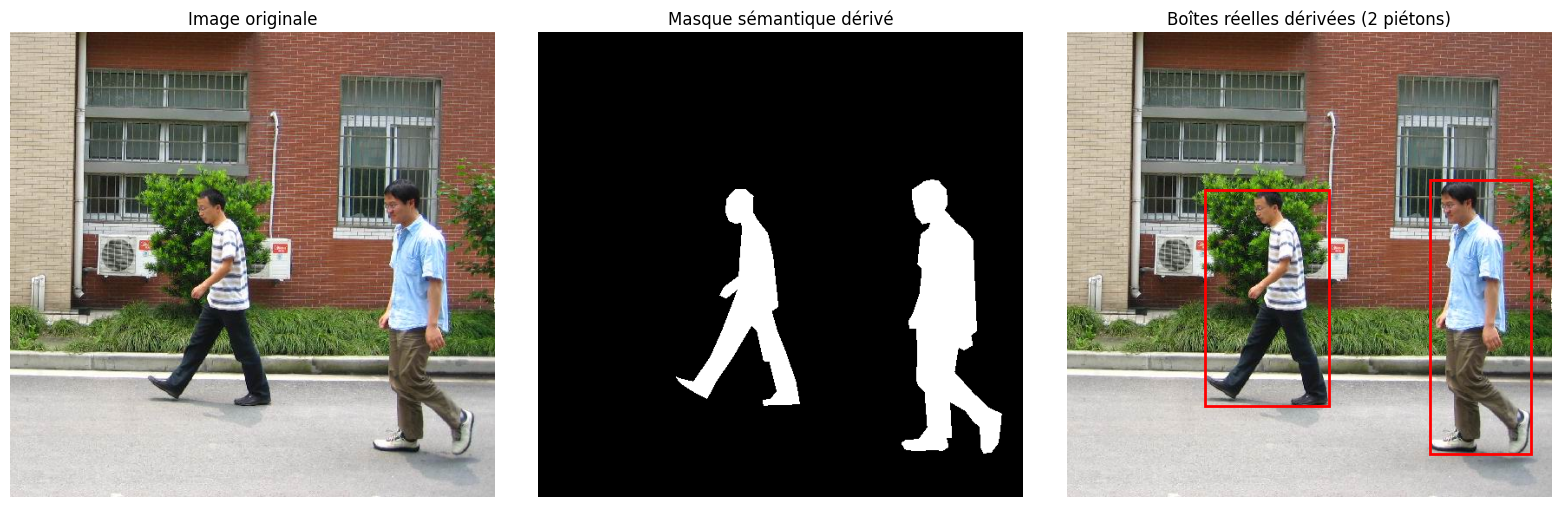

In [ ]:
# Vérifier une image et ses annotations réelles : boîtes et masques d'instances.
echantillon = penn_dataset[0]
image_exemple = echantillon["image"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(image_exemple)
axes[0].set_title("Image originale")
axes[1].imshow(echantillon["masks"].any(axis=0), cmap="gray")
axes[1].set_title("Masque sémantique dérivé")
axes[2].imshow(image_exemple)
for boite in echantillon["boxes"]:
    x1, y1, x2, y2 = boite
    axes[2].add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1,
                                     fill=False, edgecolor="red", linewidth=2))
axes[2].set_title(f"Boîtes réelles dérivées ({len(echantillon['boxes'])} piétons)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


### 4.2 Notion fondamentale : IoU (*Intersection over Union*)

L'IoU mesure le recouvrement entre une prédiction et une annotation de référence :

\[
IoU(A,B)=\frac{|A\cap B|}{|A\cup B|}
\]

Pour la détection, A et B sont des boîtes englobantes. Pour la segmentation, ce sont des ensembles de pixels. Une prédiction est souvent considérée comme correcte si son IoU dépasse un seuil, par exemple 0,50 (AP50) ou 0,75 (AP75).

In [ ]:
def iou_boites_xyxy(boite_a, boite_b):
    """IoU entre deux boîtes au format [x_min, y_min, x_max, y_max]."""
    x_gauche = max(boite_a[0], boite_b[0])
    y_haut = max(boite_a[1], boite_b[1])
    x_droite = min(boite_a[2], boite_b[2])
    y_bas = min(boite_a[3], boite_b[3])

    largeur = max(0.0, x_droite - x_gauche)
    hauteur = max(0.0, y_bas - y_haut)
    intersection = largeur * hauteur

    aire_a = max(0.0, boite_a[2] - boite_a[0]) * max(0.0, boite_a[3] - boite_a[1])
    aire_b = max(0.0, boite_b[2] - boite_b[0]) * max(0.0, boite_b[3] - boite_b[1])
    union = aire_a + aire_b - intersection
    return intersection / union if union > 0 else 0.0


def iou_masques(masque_a, masque_b):
    """IoU entre deux masques binaires de même dimension."""
    a = np.asarray(masque_a, dtype=bool)
    b = np.asarray(masque_b, dtype=bool)
    intersection = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    return float(intersection / union) if union > 0 else 0.0


### 4.3 Charger un modèle Mask R-CNN pré-entraîné

Mask R-CNN produit simultanément des boîtes, des scores de confiance, des classes et des masques d'instances. Nous retenons la classe **person** (« personne ») dans les sorties COCO. Le modèle n'est pas entraîné sur Penn-Fudan dans ce notebook : il est utilisé tel quel pour mesurer sa capacité de généralisation à ce jeu de données.

Pour calculer une courbe précision-rappel, il ne faut pas conserver uniquement les prédictions au-dessus de 0,50. Nous gardons ici les prédictions dont le score est supérieur ou égal à 0,05, puis la méthode AP classe les prédictions par score.

In [ ]:
# Le téléchargement des poids pré-entraînés se produit à la première exécution.
POIDS = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
modele = maskrcnn_resnet50_fpn(weights=POIDS).to(DEVICE)
modele.eval()

noms_classes_coco = POIDS.meta["categories"]
PERSON_ID = noms_classes_coco.index("person")
SCORE_MIN = 0.05

print("Poids utilisés :", POIDS)
print("Identifiant COCO de la classe person :", PERSON_ID)


Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 89.7MB/s]


Poids utilisés : MaskRCNN_ResNet50_FPN_Weights.COCO_V1
Identifiant COCO de la classe person : 1


In [ ]:
# Évaluer un échantillon aléatoire reproductible. Mettre None pour les 170 images.
N_IMAGES_EVALUATION = 30
rng = np.random.default_rng(SEED)
if N_IMAGES_EVALUATION is None or N_IMAGES_EVALUATION >= len(penn_dataset):
    indices_evaluation = np.arange(len(penn_dataset))
else:
    indices_evaluation = np.sort(
        rng.choice(len(penn_dataset), size=N_IMAGES_EVALUATION, replace=False)
    )

annotations = {}
predictions = {}
images_evaluation = {}

@torch.inference_mode()
def predire_image(image_rgb):
    """Exécute Mask R-CNN et ne conserve que les prédictions de personnes."""
    tenseur_image = TF.to_tensor(Image.fromarray(image_rgb)).to(DEVICE)
    sortie = modele([tenseur_image])[0]

    garder = (sortie["labels"] == PERSON_ID) & (sortie["scores"] >= SCORE_MIN)
    boites = sortie["boxes"][garder].detach().cpu().numpy().astype(np.float32)
    scores = sortie["scores"][garder].detach().cpu().numpy().astype(np.float32)
    # Sortie du réseau : (N, 1, H, W). On obtient ici (N, H, W).
    masques = sortie["masks"][garder, 0].detach().cpu().numpy() >= 0.5

    return {"boxes": boites, "scores": scores, "masks": masques}

for position, indice in enumerate(indices_evaluation, start=1):
    element = penn_dataset[int(indice)]
    image_id = element["image_id"]
    images_evaluation[image_id] = element["image"]
    annotations[image_id] = {
        "boxes": element["boxes"],
        "masks": element["masks"],
    }
    predictions[image_id] = predire_image(element["image"])

    if position % 5 == 0 or position == len(indices_evaluation):
        print(f"Inférence : {position}/{len(indices_evaluation)} images")

nb_gt = sum(len(v["boxes"]) for v in annotations.values())
nb_pred = sum(len(v["boxes"]) for v in predictions.values())
print(f"Instances réelles : {nb_gt} | Instances prédites retenues : {nb_pred}")


Inférence : 5/30 images
Inférence : 10/30 images
Inférence : 15/30 images
Inférence : 20/30 images
Inférence : 25/30 images
Inférence : 30/30 images
Instances réelles : 84 | Instances prédites retenues : 363


### 4.4 AP et mAP : définition et calcul

Pour un seuil d'IoU donné :

1. toutes les prédictions sont triées par score de confiance décroissant ;
2. une prédiction est un vrai positif si elle correspond à une annotation non encore appariée dans la même image et si l'IoU atteint le seuil ;
3. les prédictions en doublon ou sans correspondance sont des faux positifs ;
4. on construit la courbe précision-rappel ;
5. l'**AP** (*Average Precision*) est l'aire sous cette courbe, approximée ici par une interpolation à 101 points de rappel.

L'**AP50** utilise IoU ≥ 0,50 ; l'**AP75** utilise IoU ≥ 0,75. La **mAP@[.50:.95]** est la moyenne des AP calculées aux seuils 0,50, 0,55, …, 0,95.

> **Note méthodologique :** l'implémentation ci-dessous est un évaluateur pédagogique à une classe, inspiré du protocole COCO (seuils d'IoU et interpolation à 101 points). Elle ne reproduit pas tous les détails de `pycocotools` : gestion des zones ignorées/crowd, limites `maxDets`, tranches de taille et règles complètes d'appariement. Pour un score de benchmark officiel, utiliser l'évaluateur COCO officiel et des annotations au format COCO.

In [ ]:
def ap_101_points(rappel, precision):
    """AP par interpolation de la précision aux 101 niveaux de rappel COCO."""
    niveaux_rappel = np.linspace(0.0, 1.0, 101)
    precisions_interpolees = []
    for niveau in niveaux_rappel:
        valeurs = precision[rappel >= niveau]
        precisions_interpolees.append(float(valeurs.max()) if len(valeurs) else 0.0)
    return float(np.mean(precisions_interpolees))


def calculer_ap(annotations, predictions, seuil_iou, fonction_iou, cle_objets):
    """Calcule l'AP d'une classe sur plusieurs images avec appariement glouton.

    `cle_objets` vaut 'boxes' pour la détection ou 'masks' pour l'instance segmentation.
    Chaque instance réelle ne peut être appariée qu'à une seule prédiction.
    """
    total_gt = sum(len(ann[cle_objets]) for ann in annotations.values())
    if total_gt == 0:
        raise ValueError("Aucune instance de référence : l'AP n'est pas définie.")

    liste_predictions = []
    for image_id, pred in predictions.items():
        objets_predits = pred[cle_objets]
        for indice_objet, score in enumerate(pred["scores"]):
            liste_predictions.append((float(score), image_id, indice_objet))

    liste_predictions.sort(key=lambda item: item[0], reverse=True)
    deja_apparie = {
        image_id: np.zeros(len(ann[cle_objets]), dtype=bool)
        for image_id, ann in annotations.items()
    }

    vrais_positifs = np.zeros(len(liste_predictions), dtype=np.float64)
    faux_positifs = np.zeros(len(liste_predictions), dtype=np.float64)

    for rang, (_, image_id, indice_pred) in enumerate(liste_predictions):
        objet_predit = predictions[image_id][cle_objets][indice_pred]
        objets_reels = annotations[image_id][cle_objets]

        if len(objets_reels) == 0:
            faux_positifs[rang] = 1.0
            continue

        ious = np.array([
            fonction_iou(objet_predit, objet_reel)
            for objet_reel in objets_reels
        ])
        # On cherche l'annotation non encore appariée ayant l'IoU maximal.
        ordre = np.argsort(ious)[::-1]
        meilleur = next((j for j in ordre if not deja_apparie[image_id][j]), None)

        if meilleur is not None and ious[meilleur] >= seuil_iou:
            vrais_positifs[rang] = 1.0
            deja_apparie[image_id][meilleur] = True
        else:
            faux_positifs[rang] = 1.0

    cumul_vp = np.cumsum(vrais_positifs)
    cumul_fp = np.cumsum(faux_positifs)
    rappel = cumul_vp / total_gt
    precision = cumul_vp / np.maximum(cumul_vp + cumul_fp, np.finfo(float).eps)
    ap = ap_101_points(rappel, precision)
    return ap, precision, rappel


def evaluer_map(annotations, predictions, cle_objets, fonction_iou):
    """Retourne AP50, AP75 et mAP moyenne aux seuils 0,50 à 0,95."""
    seuils = np.arange(0.50, 0.951, 0.05)
    aps = {}
    courbe_precision = None
    courbe_rappel = None
    for seuil in seuils:
        ap, precision, rappel = calculer_ap(
            annotations, predictions, float(seuil), fonction_iou, cle_objets
        )
        aps[round(float(seuil), 2)] = ap
        if np.isclose(seuil, 0.50):
            courbe_precision, courbe_rappel = precision, rappel

    return {
        "AP50": aps[0.5],
        "AP75": aps[0.75],
        "mAP_50_95": float(np.mean(list(aps.values()))),
        "AP_par_seuil": aps,
        "precision": courbe_precision,
        "rappel": courbe_rappel,
    }


### 4.5 Résultats de détection

Nous comparons les boîtes produites par Mask R-CNN aux boîtes dérivées des masques Penn-Fudan. La classe évaluée est « piéton ».

,Métrique,Valeur
0,AP50,0.9925
1,AP75,0.9284
2,mAP@[.50:.95],0.8229


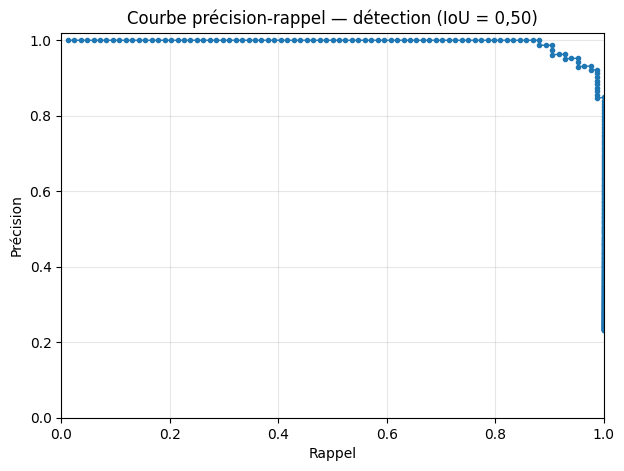

AP par seuil d'IoU :


,Seuil IoU,AP
0,0.500000,0.9925
1,0.550000,0.9797
2,0.600000,0.9797
3,0.650000,0.9688
4,0.700000,0.9544
5,0.750000,0.9284
6,0.800000,0.8893
7,0.850000,0.8625
8,0.900000,0.5635
9,0.950000,0.1100


In [ ]:
resultats_detection = evaluer_map(
    annotations=annotations,
    predictions=predictions,
    cle_objets="boxes",
    fonction_iou=iou_boites_xyxy,
)

resume_detection = pd.DataFrame({
    "Métrique": ["AP50", "AP75", "mAP@[.50:.95]"],
    "Valeur": [
        resultats_detection["AP50"],
        resultats_detection["AP75"],
        resultats_detection["mAP_50_95"],
    ],
})
display(resume_detection.style.format({"Valeur": "{:.4f}"}))

plt.figure(figsize=(7, 5))
plt.plot(resultats_detection["rappel"], resultats_detection["precision"],
         marker=".", linewidth=1)
plt.xlabel("Rappel")
plt.ylabel("Précision")
plt.title("Courbe précision-rappel — détection (IoU = 0,50)")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.show()

print("AP par seuil d'IoU :")
display(pd.DataFrame({
    "Seuil IoU": list(resultats_detection["AP_par_seuil"].keys()),
    "AP": list(resultats_detection["AP_par_seuil"].values()),
}).style.format({"AP": "{:.4f}"}))


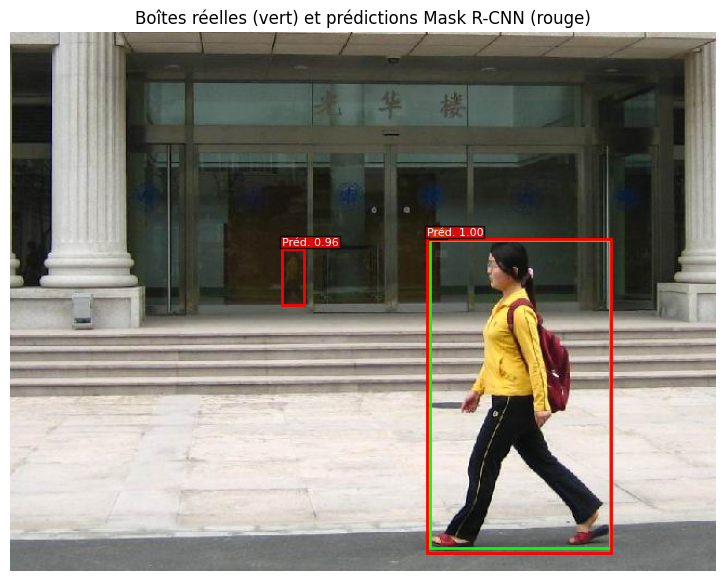

In [ ]:
# Visualiser une prédiction du modèle et l'annotation de référence.
def afficher_boites(ax, boites, couleur, prefixe, scores=None):
    for i, boite in enumerate(boites):
        x1, y1, x2, y2 = boite
        ax.add_patch(plt.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            fill=False, edgecolor=couleur, linewidth=2
        ))
        texte = prefixe if scores is None else f"{prefixe} {scores[i]:.2f}"
        ax.text(x1, max(0, y1-4), texte, color="white", fontsize=8,
                bbox=dict(facecolor=couleur, alpha=0.8, pad=1))

image_id_visu = next(iter(images_evaluation))
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(images_evaluation[image_id_visu])
afficher_boites(ax, annotations[image_id_visu]["boxes"], "lime", "GT")
afficher_boites(ax, predictions[image_id_visu]["boxes"], "red", "Préd.",
                predictions[image_id_visu]["scores"])
ax.set_title("Boîtes réelles (vert) et prédictions Mask R-CNN (rouge)")
ax.axis("off")
plt.show()


### 4.6 Interpréter les métriques de détection

- Une **IoU élevée** signifie que la boîte prédite est bien localisée.
- **AP50** est plus tolérante à une localisation approximative que **AP75**.
- **mAP@[.50:.95]** est plus stricte, car elle moyenne plusieurs seuils d'IoU.
- Un **faux positif** peut être une boîte sur un objet inexistant, une mauvaise classe ou un doublon d'une instance déjà détectée.
- Un **faux négatif** correspond à une instance réelle non détectée.

L'AP est préférable à une seule précision/rappel calculée à un seuil de score arbitraire, car elle résume le comportement sur plusieurs seuils de confiance.

## 5. Segmentation sémantique avec Penn-Fudan

### 5.1 Différence entre segmentation sémantique et instance

La **segmentation sémantique** attribue une classe à chaque pixel. Dans notre expérience binaire, chaque pixel est « piéton » ou « arrière-plan ». Deux piétons qui se touchent peuvent appartenir à la même région sémantique : leur identité individuelle n'est pas nécessaire.

Pour obtenir la vérité terrain sémantique, nous réunissons les masques d'instances fournis par Penn-Fudan. Pour obtenir la prédiction sémantique, nous réunissons les masques de personnes prédits par Mask R-CNN.

In [ ]:
def masque_semantique(masques_instances, forme):
    """Fusionne plusieurs masques d'instances en un masque binaire de classe."""
    if len(masques_instances) == 0:
        return np.zeros(forme, dtype=bool)
    return np.asarray(masques_instances, dtype=bool).any(axis=0)


def calculer_matrice_confusion_pixels(annotations, predictions):
    """Construit une matrice de confusion globale sur tous les pixels évalués.

    Classe 0 : arrière-plan ; classe 1 : piéton.
    Les pixels de toutes les images sont agrégés avant le calcul des métriques.
    """
    matrice = np.zeros((2, 2), dtype=np.int64)
    for image_id in annotations:
        gt_masques = annotations[image_id]["masks"]
        hauteur, largeur = images_evaluation[image_id].shape[:2]
        gt = masque_semantique(gt_masques, (hauteur, largeur)).astype(np.uint8)
        pred = masque_semantique(predictions[image_id]["masks"], (hauteur, largeur)).astype(np.uint8)

        # Encodage de la paire (vraie classe, classe prédite) dans {0,1,2,3}.
        codes = 2 * gt.ravel() + pred.ravel()
        matrice += np.bincount(codes, minlength=4).reshape(2, 2)
    return matrice


def metriques_semantiques_depuis_cm(matrice):
    """Calcule accuracy pixel, IoU par classe, mIoU et Dice/precision/rappel."""
    matrice = np.asarray(matrice, dtype=np.float64)
    vrais = np.diag(matrice)
    total_par_classe = matrice.sum(axis=1)
    pred_par_classe = matrice.sum(axis=0)
    union = total_par_classe + pred_par_classe - vrais

    iou_par_classe = np.divide(
        vrais, union, out=np.zeros_like(vrais), where=union > 0
    )
    accuracy_pixel = vrais.sum() / matrice.sum() if matrice.sum() else 0.0
    precision_pieton = vrais[1] / pred_par_classe[1] if pred_par_classe[1] else 0.0
    rappel_pieton = vrais[1] / total_par_classe[1] if total_par_classe[1] else 0.0
    dice_pieton = (
        2 * vrais[1] / (total_par_classe[1] + pred_par_classe[1])
        if (total_par_classe[1] + pred_par_classe[1]) else 0.0
    )

    return {
        "Pixel accuracy": accuracy_pixel,
        "IoU arrière-plan": iou_par_classe[0],
        "IoU piéton": iou_par_classe[1],
        "mIoU": iou_par_classe.mean(),
        "Précision piéton": precision_pieton,
        "Rappel piéton": rappel_pieton,
        "Dice piéton": dice_pieton,
    }


In [ ]:
cm_pixels = calculer_matrice_confusion_pixels(annotations, predictions)
print("Matrice de confusion des pixels (lignes = vérité terrain, colonnes = prédiction) :")
display(pd.DataFrame(
    cm_pixels,
    index=["Vrai arrière-plan", "Vrai piéton"],
    columns=["Prédit arrière-plan", "Prédit piéton"],
))

metriques_sem = metriques_semantiques_depuis_cm(cm_pixels)
display(pd.DataFrame({
    "Métrique": list(metriques_sem.keys()),
    "Valeur": list(metriques_sem.values()),
}).style.format({"Valeur": "{:.4f}"}))


Matrice de confusion des pixels (lignes = vérité terrain, colonnes = prédiction) :


,Prédit arrière-plan,Prédit piéton
Vrai arrière-plan,4642157,272625
Vrai piéton,41929,1117958


,Métrique,Valeur
0,Pixel accuracy,0.9482
1,IoU arrière-plan,0.9365
2,IoU piéton,0.7804
3,mIoU,0.8585
4,Précision piéton,0.8039
5,Rappel piéton,0.9639
6,Dice piéton,0.8767


### 5.2 Formules de segmentation sémantique

Pour une classe donnée (ici, piéton) :

\[
IoU = \frac{VP}{VP+FP+FN}
\]
\[
Dice = \frac{2VP}{2VP+FP+FN}
\]

- **Pixel accuracy** : proportion de pixels correctement classés.
- **IoU par classe** : recouvrement entre la région prédite et la région réelle pour cette classe.
- **mIoU** : moyenne arithmétique des IoU des classes (arrière-plan et piéton ici).
- **Dice** : mesure de recouvrement proche du F1-score, calculée au niveau des pixels.

L'accuracy pixel peut être trompeuse si l'arrière-plan occupe la majeure partie de l'image. Il est donc important de regarder également l'IoU du piéton et la mIoU.

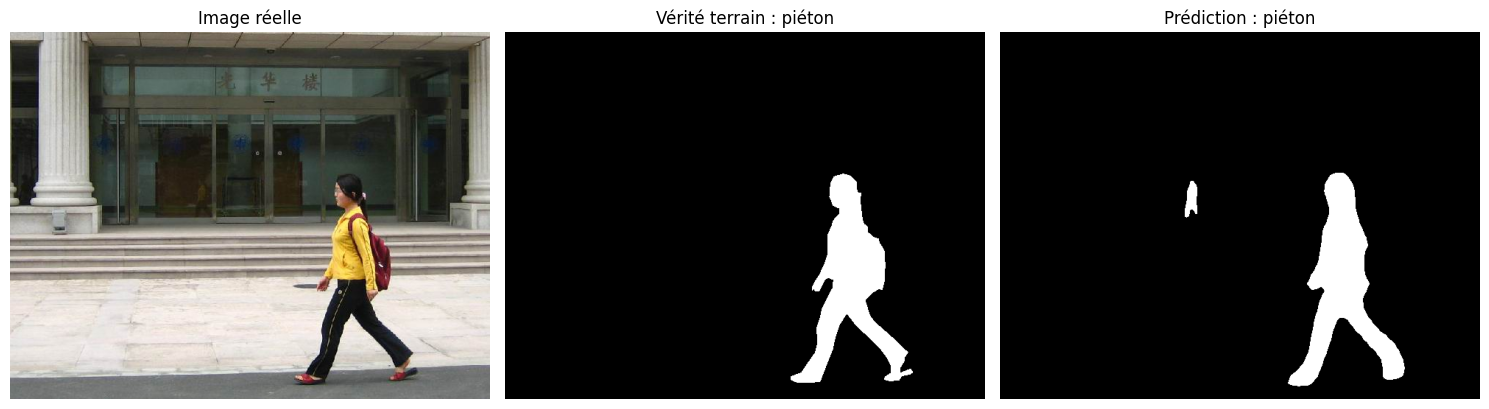

In [ ]:
# Comparer, sur une image réelle, les régions sémantiques réelles et prédites.
image_id_seg = image_id_visu
image_seg = images_evaluation[image_id_seg]
h, w = image_seg.shape[:2]
gt_sem = masque_semantique(annotations[image_id_seg]["masks"], (h, w))
pred_sem = masque_semantique(predictions[image_id_seg]["masks"], (h, w))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image_seg)
axes[0].set_title("Image réelle")
axes[1].imshow(gt_sem, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Vérité terrain : piéton")
axes[2].imshow(pred_sem, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Prédiction : piéton")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 6. Segmentation par instance avec Penn-Fudan

### 6.1 Principe

La segmentation par instance doit non seulement reconnaître la classe de chaque pixel, mais aussi séparer les objets individuels. Dans cette expérience, deux piétons proches doivent correspondre à deux masques distincts.

Nous utilisons les **masques d'instances** fournis dans Penn-Fudan et ceux prédits par Mask R-CNN. La métrique principale est l'AP de masque, où l'IoU est calculée sur les pixels plutôt que sur les boîtes.

,Métrique,Valeur
0,Mask AP50,0.9925
1,Mask AP75,0.8946
2,Mask mAP@[.50:.95],0.7376


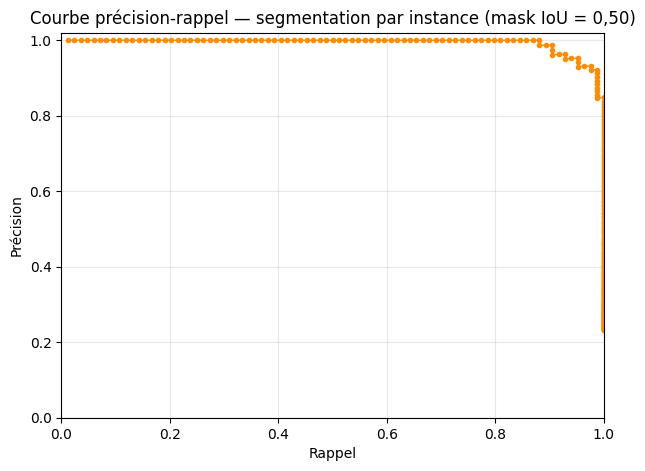

In [ ]:
resultats_instance = evaluer_map(
    annotations=annotations,
    predictions=predictions,
    cle_objets="masks",
    fonction_iou=iou_masques,
)

resume_instance = pd.DataFrame({
    "Métrique": ["Mask AP50", "Mask AP75", "Mask mAP@[.50:.95]"],
    "Valeur": [
        resultats_instance["AP50"],
        resultats_instance["AP75"],
        resultats_instance["mAP_50_95"],
    ],
})
display(resume_instance.style.format({"Valeur": "{:.4f}"}))

plt.figure(figsize=(7, 5))
plt.plot(resultats_instance["rappel"], resultats_instance["precision"],
         marker=".", linewidth=1, color="darkorange")
plt.xlabel("Rappel")
plt.ylabel("Précision")
plt.title("Courbe précision-rappel — segmentation par instance (mask IoU = 0,50)")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.show()


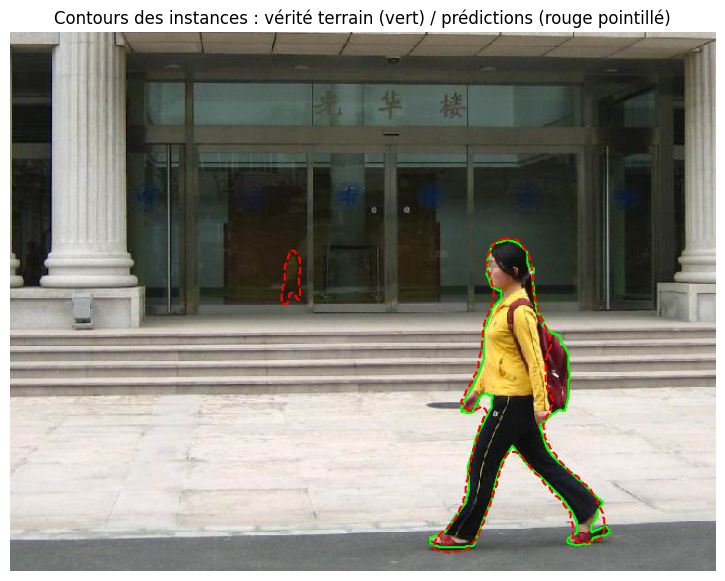

In [ ]:
# Afficher les contours des instances réelles et prédites sur une image Penn-Fudan.
def tracer_contours(ax, masques, couleur, style="-"):
    for masque in masques:
        # Le contour est calculé à partir du masque binaire de l'instance.
        ax.contour(masque.astype(float), levels=[0.5], colors=[couleur],
                   linewidths=1.5, linestyles=style)

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(images_evaluation[image_id_visu])
tracer_contours(ax, annotations[image_id_visu]["masks"], "lime")
tracer_contours(ax, predictions[image_id_visu]["masks"], "red", "--")
ax.set_title("Contours des instances : vérité terrain (vert) / prédictions (rouge pointillé)")
ax.axis("off")
plt.show()


### 6.2 Pourquoi l'IoU de masque est différente de l'IoU de boîte ?

Deux boîtes peuvent avoir une bonne IoU alors que les contours des objets sont mal estimés. À l'inverse, une boîte légèrement décalée peut contenir un masque assez fidèle. La segmentation par instance pénalise donc les erreurs de forme et de contour que l'évaluation des seules boîtes ne détecte pas.

Dans les benchmarks de type COCO, l'AP de masque est calculée selon plusieurs seuils d'IoU, comme l'AP de détection, mais l'appariement compare les masques pixel par pixel.

## 7. Comparaison synthétique des familles de métriques

| Tâche | Unité évaluée | Métriques usuelles | Erreurs principalement mesurées |
|---|---|---|---|
| Classification | Image entière | Accuracy, précision, rappel, F1, ROC-AUC, Top-k | Classe incorrecte |
| Détection | Objet / boîte | IoU, AP50, AP75, mAP | Objet manqué, faux objet, localisation imprécise, doublon |
| Segmentation sémantique | Pixel / classe | Pixel accuracy, IoU, mIoU, Dice | Pixels attribués à la mauvaise classe |
| Segmentation par instance | Objet / masque | Mask IoU, Mask AP, Mask mAP | Instance manquée, instance en trop, mauvais contour ou fusion d'instances |

### Comment choisir ?

- Si chaque image doit recevoir une seule étiquette : commencez par l'accuracy et le F1 macro.
- Si chaque objet doit être localisé : privilégiez AP/mAP et inspectez les seuils d'IoU.
- Si chaque pixel doit recevoir une classe : utilisez IoU par classe et mIoU ; ne vous limitez pas à l'accuracy pixel.
- Si les objets de même classe doivent rester séparés : utilisez les métriques de segmentation par instance (Mask AP).

---

## 8. Tableau récapitulatif des résultats de cette exécution

La cellule suivante rassemble les scores obtenus sur les sous-ensembles réellement téléchargés/évalués. Les chiffres peuvent varier légèrement avec les versions logicielles, les poids du modèle, le matériel et le choix des images Penn-Fudan.

In [ ]:
tableau_final = pd.DataFrame([
    {"Tâche": "Classification CIFAR-10", "Métrique": "Accuracy", "Score": accuracy_score(y_test, y_pred)},
    {"Tâche": "Classification CIFAR-10", "Métrique": "F1 macro", "Score": f1_score(y_test, y_pred, average="macro", zero_division=0)},
    {"Tâche": "Classification CIFAR-10", "Métrique": "Top-5 accuracy", "Score": top_k_accuracy(y_test, y_proba, k=5)},
    {"Tâche": "Détection Penn-Fudan", "Métrique": "AP50", "Score": resultats_detection["AP50"]},
    {"Tâche": "Détection Penn-Fudan", "Métrique": "AP75", "Score": resultats_detection["AP75"]},
    {"Tâche": "Détection Penn-Fudan", "Métrique": "mAP@[.50:.95]", "Score": resultats_detection["mAP_50_95"]},
    {"Tâche": "Segmentation sémantique", "Métrique": "mIoU", "Score": metriques_sem["mIoU"]},
    {"Tâche": "Segmentation sémantique", "Métrique": "Dice piéton", "Score": metriques_sem["Dice piéton"]},
    {"Tâche": "Segmentation par instance", "Métrique": "Mask AP50", "Score": resultats_instance["AP50"]},
    {"Tâche": "Segmentation par instance", "Métrique": "Mask mAP@[.50:.95]", "Score": resultats_instance["mAP_50_95"]},
])
display(tableau_final.style.format({"Score": "{:.4f}"}))


,Tâche,Métrique,Score
0,Classification CIFAR-10,Accuracy,0.9315
1,Classification CIFAR-10,F1 macro,0.9315
2,Classification CIFAR-10,Top-5 accuracy,0.9973
3,Détection Penn-Fudan,AP50,0.9925
4,Détection Penn-Fudan,AP75,0.9284
5,Détection Penn-Fudan,mAP@[.50:.95],0.8229
6,Segmentation sémantique,mIoU,0.8585
7,Segmentation sémantique,Dice piéton,0.8767
8,Segmentation par instance,Mask AP50,0.9925
9,Segmentation par instance,Mask mAP@[.50:.95],0.7376


In [ ]:
print("=== Configuration de l'expérience ===")
print(f"CIFAR-10 : {len(train_dataset)} images entraînement / {len(val_dataset)} validation / {len(dataset_test)} test")
print(f"Classification : ResNet-18 adapté à CIFAR-10 ; meilleure époque = {meilleure_epoque}")
print(f"Régularisation : weight_decay={WEIGHT_DECAY}, dropout=0.25, label_smoothing={LABEL_SMOOTHING}")
print(f"Penn-Fudan : {len(images_evaluation)} images évaluées")
print(f"Penn-Fudan : {nb_gt} instances annotées / {nb_pred} instances prédites")
print(f"Modèle détection/segmentation : Mask R-CNN ResNet-50 FPN, poids {POIDS}")
print(f"Seuil minimal de score des prédictions : {SCORE_MIN}")

=== Configuration de l'expérience ===
CIFAR-10 : 45000 images entraînement / 5000 validation / 10000 test
Classification : ResNet-18 adapté à CIFAR-10 ; meilleure époque = 30
Régularisation : weight_decay=0.0005, dropout=0.25, label_smoothing=0.05
Penn-Fudan : 30 images évaluées
Penn-Fudan : 84 instances annotées / 363 instances prédites
Modèle détection/segmentation : Mask R-CNN ResNet-50 FPN, poids MaskRCNN_ResNet50_FPN_Weights.COCO_V1
Seuil minimal de score des prédictions : 0.05
